# 04 - Final predictions and submission

**Notebook 4 of 4.** This notebook reproduces the submission end to end from the raw files: clean, fit on all eligible training rows, predict the 12,000 validation loads and the 31 December chart rows, validate the files, run the **unchanged** `score.py`, and check that the result matches the script-based pipeline.

Two rules apply throughout. **No validation labels exist**, so nothing here measures validation accuracy; accuracy statements refer to the cross-validation in notebook 3 and are labelled as such. And every December number is a *forecast under stated assumptions*, whose sensitivity is quantified in section 6.

In [1]:
import sys
from pathlib import Path

# Locate the project root (the folder containing common.py) from wherever the kernel was started.
_here = Path.cwd().resolve()
ROOT = next((b for b in [_here, *_here.parents] if (b / "common.py").is_file()),
            next(iter(sorted(p.parent for p in _here.glob("*/common.py"))), None))
assert ROOT is not None, "common.py not found: open this notebook from inside the project folder"
sys.path.insert(0, str(ROOT))

from notebook_support import setup, save_fig, TEAL, GREY, RED, ORANGE

import hashlib, subprocess
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import common
from common import (FreightRateModel, clean_inputs, daily_market_index, days_to_quarter_end, flag_label_outliers, linear_features, load_data)
from train_and_predict import complete_december_inputs

# train_and_predict selects the non-interactive Agg backend on import; restore inline plots
%matplotlib inline

P = setup("04_submission")
train, valid, template, december = load_data(P["data"])
OUT = P["outputs"]; print("writing to:", OUT)

writing to: C:\Users\MASTER\Downloads\Freight Challenge\freight-rate-challenge\outputs\notebooks


## 1. Load and clean

**Question.** What does the final cleaning pipeline do to each file?

**Why it matters.** The same repairs must be applied to training, validation and December inputs.

In [2]:
dmi = daily_market_index(train, valid)          # features only
summary = pd.DataFrame({
    "rows": [len(train), len(valid), len(december)],
    "negative weights (repaired by abs)": [(train.weight < 0).sum(), (valid.weight < 0).sum(), (december.weight < 0).sum()],
    "missing weight (left as NaN)": [train.weight.isna().sum(), valid.weight.isna().sum(), december.weight.isna().sum()],
    "missing market_index (not needed: daily mean)": [train.market_index.isna().sum() if "market_index" in train else 0, valid.market_index.isna().sum(), "n/a"],
}, index=["train_test", "validation", "december"])
display(summary)
labels_ok = flag_label_outliers(clean_inputs(train), dmi)
display(Markdown(f"* training rows kept after label-corruption filtering: **{labels_ok.sum():,}** of {len(train):,} (**{(~labels_ok).sum()}** dropped from *training only*)  \n"
                 f"* the validation file has no label column, so there is nothing to filter there: **{'posted_rate' not in valid.columns}**  \n"
                 f"* the daily market index covers **{dmi.index.min().date()} to {dmi.index.max().date()}** ({len(dmi)} days)"))

,rows,negative weights (repaired by abs),missing weight (left as NaN),missing market_index (not needed: daily mean)
train_test,48000,292,300,374
validation,12000,145,165,249
december,31,0,0,n/a


* training rows kept after label-corruption filtering: **47,323** of 48,000 (**677** dropped from *training only*)  
* the validation file has no label column, so there is nothing to filter there: **True**  
* the daily market index covers **2025-01-01 to 2025-12-31** (365 days)

## 2. Fit the final model

**Question.** Which rows are used and what does the fitted model look like?

**Why it matters.** The final model uses all eligible history; no validation labels exist.

In [3]:
model = FreightRateModel(dmi).fit(train)
names = ["log_distance", "log_distance^2", "flatbed", "reefer", "daily_market_index", "trend (per 100 days)", "quarter_end_ramp"]
coef = pd.Series(model.linear_.coef_ / model.sd_, index=names)
display(Markdown(f"trained on **{model.n_train_:,}** rows; GBM iterations **{model.gbm_.n_iter_}**"))
display(coef.to_frame("coefficient (log-price per unit)").T)

trained on **47,323** rows; GBM iterations **300**

,log_distance,log_distance^2,flatbed,reefer,daily_market_index,trend (per 100 days),quarter_end_ramp
coefficient (log-price per unit),0.7449,0.0096,0.0802,0.1215,0.1425,0.0197,0.0389


## 3. Predict the 12,000 validation loads, with sanity checks

**Question.** Are the predictions complete, valid and plausible?

**Why it matters.** Without labels we cannot measure accuracy, but we can rule out gross failures.

,passed
one prediction per validation row,True
no NaN,True
no inf,True
all strictly positive,True
validation load_id unique,True
IDs identical to the template,True


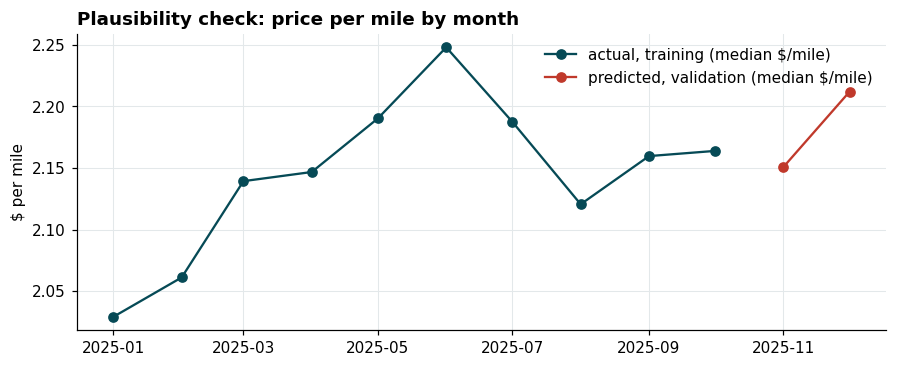

,training actual,validation predicted
count,"48,000.0000","12,000.0000"
mean,"2,374.0000","2,397.1000"
std,"1,486.5000","1,382.0000"
min,57.2000,195.5000
25%,"1,251.6000","1,294.4000"
50%,"2,030.8000","2,074.4000"
75%,"3,330.8000","3,398.1000"
max,"25,533.0000","7,073.5000"


predicted median $/mile for rows touching an unseen city: **2.186** vs other rows **2.182** (should be similar)

In [4]:
pred = model.predict(valid)
checks = {
    "one prediction per validation row": len(pred) == len(valid) == 12_000,
    "no NaN": not np.isnan(pred).any(), "no inf": bool(np.isfinite(pred).all()), "all strictly positive": bool((pred > 0).all()),
    "validation load_id unique": valid.load_id.is_unique, "IDs identical to the template": set(valid.load_id) == set(template.load_id),
}
display(pd.Series(checks, name="passed").to_frame()); assert all(checks.values())

# Plausibility (NOT accuracy): predicted price per mile by month vs actual price per mile in training
v = valid.assign(pred=pred, rpm=pred / valid.distance); t = train.assign(rpm=train.posted_rate / train.distance)
fig, ax = plt.subplots(figsize=(9.5, 3.5))
am = t.groupby(t.date.dt.to_period("M")).rpm.median(); pm = v.groupby(v.date.dt.to_period("M")).rpm.median()
ax.plot(am.index.to_timestamp(), am.values, marker="o", color=TEAL, label="actual, training (median $/mile)")
ax.plot(pm.index.to_timestamp(), pm.values, marker="o", color=RED, label="predicted, validation (median $/mile)")
ax.set_title("Plausibility check: price per mile by month"); ax.set_ylabel("$ per mile"); ax.legend(frameon=False)
save_fig(fig, P, "plausibility"); plt.show()
display(pd.DataFrame({"training actual": t.posted_rate.describe(), "validation predicted": pd.Series(pred).describe()}).round(1))
unseen = ~(valid.pickup.isin(set(train.pickup) | set(train.delivery)) & valid.delivery.isin(set(train.pickup) | set(train.delivery)))
display(Markdown(f"predicted median $/mile for rows touching an unseen city: **{v[unseen].rpm.median():.3f}** vs other rows **{v[~unseen].rpm.median():.3f}** (should be similar)"))

## 4. Populate the template and save the submission

**Question.** Does the output have exactly the required columns, IDs and order?

**Why it matters.** The scorer rejects anything else; a reviewer will diff the file against the template.

In [5]:
sub = pd.DataFrame({"load_id": valid.load_id.to_numpy(), "predicted_rate": np.round(pred, 2)})
filled = template[["load_id"]].merge(sub, on="load_id", how="left", validate="one_to_one")     # keeps the template's row order
assert filled.predicted_rate.notna().all() and len(filled) == len(template) and (filled.load_id.values == template.load_id.values).all()
SUB_PATH = OUT / "validation_predictions.csv"
filled.to_csv(SUB_PATH, index=False)
reread = pd.read_csv(SUB_PATH)
display(Markdown(f"saved **{SUB_PATH}**; columns exactly `{list(reread.columns)}`; rows **{len(reread):,}**; order identical to template: **{(reread.load_id.values == template.load_id.values).all()}**"))
display(reread.head())

saved **/home/claude/freight-rate-challenge/outputs/notebooks/validation_predictions.csv**; columns exactly `['load_id', 'predicted_rate']`; rows **12,000**; order identical to template: **True**

,load_id,predicted_rate
0,TE-000001,850.9100
1,TE-000002,"5,109.3500"
2,TE-000003,"5,208.1700"
3,TE-000004,"4,017.8400"
4,TE-000005,"1,879.7500"


## 5. December chart: predictions and what drives them

**Question.** What does the model predict for Lexington to Fort Wayne on each December day, and which components create the shape?

**Why it matters.** The chart is only a function of the date; understanding its components is the whole story.

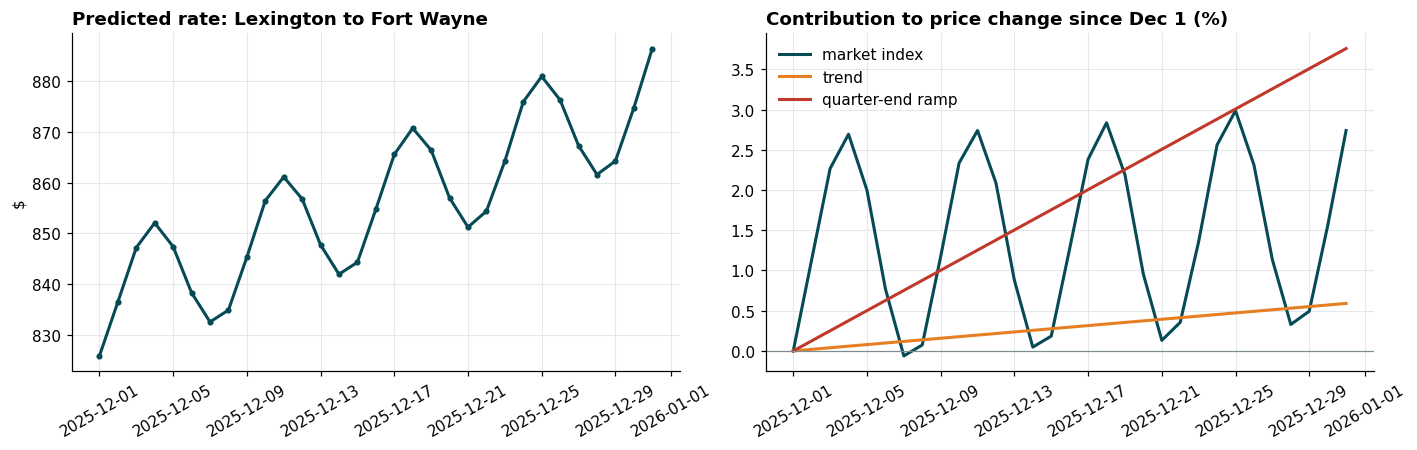

,market index,predicted $
weekday,,
Monday,0.8505,844.7312
Tuesday,0.9261,855.1196
Wednesday,1.0074,866.3434
Thursday,1.0324,866.2487
Friday,0.9856,861.7360
Saturday,0.9005,852.5881
Sunday,0.8427,846.8255


* Dec 1: **$826**, Dec 31: **$887** (**+7.3%**); range **$826 - $887**  
* share of the Dec 1 -> Dec 31 log change from: market index **39%**, trend **8%**, ramp **53%**

In [6]:
dec_in = complete_december_inputs(december, train, valid)          # adds coordinates (city lookup); dmi supplies the market level
dec_pred = model.predict(dec_in)
dec_out = december.copy(); dec_out["predicted_rate"] = np.round(dec_pred, 2); dec_out["date"] = dec_out["date"].dt.strftime("%Y-%m-%d")
DEC_PATH = OUT / "december_chart_inputs.csv"; dec_out.to_csv(DEC_PATH, index=False)

# decompose the log-price movement relative to Dec 1 into the three time-varying linear components
dates = pd.to_datetime(dec_out.date)
comp = pd.DataFrame({
    "market index": coef["daily_market_index"] * (dates.map(dmi).to_numpy() - dmi[dates.iloc[0]]),
    "trend": coef["trend (per 100 days)"] * ((dates - common.T0).dt.days.to_numpy() - (dates.iloc[0] - common.T0).days) / 100,
    "quarter-end ramp": coef["quarter_end_ramp"] * (np.clip(1 - days_to_quarter_end(dates) / common.RAMP_DAYS, 0, 1) - np.clip(1 - days_to_quarter_end(dates.iloc[:1]) / common.RAMP_DAYS, 0, 1)[0]),
}, index=dates)
comp["trees (constant for this lane)"] = np.log(dec_pred) - np.log(dec_pred[0]) - comp.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(dates, dec_pred, color=TEAL, marker="o", ms=3, lw=2); axes[0].set_title("Predicted rate: Lexington to Fort Wayne"); axes[0].set_ylabel("$"); axes[0].tick_params(axis="x", rotation=30)
for col, color in zip(comp.columns[:3], [TEAL, ORANGE, RED]): axes[1].plot(dates, 100 * comp[col], label=col, color=color, lw=2)
axes[1].axhline(0, color=GREY, lw=0.8); axes[1].set_title("Contribution to price change since Dec 1 (%)"); axes[1].legend(frameon=False); axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout(); save_fig(fig, P, "december_decomposition"); plt.show()

wk = pd.DataFrame({"weekday": dates.dt.day_name(), "market index": dates.map(dmi).to_numpy(), "predicted $": dec_pred}).groupby("weekday").mean().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
display(wk)
display(Markdown(f"* Dec 1: **${dec_pred[0]:,.0f}**, Dec 31: **${dec_pred[-1]:,.0f}** (**{dec_pred[-1] / dec_pred[0] - 1:+.1%}**); range **${dec_pred.min():,.0f} - ${dec_pred.max():,.0f}**  \n"
                 f"* share of the Dec 1 -> Dec 31 log change from: market index **{comp['market index'].iloc[-1] / np.log(dec_pred[-1] / dec_pred[0]):.0%}**, trend **{comp['trend'].iloc[-1] / np.log(dec_pred[-1] / dec_pred[0]):.0%}**, ramp **{comp['quarter-end ramp'].iloc[-1] / np.log(dec_pred[-1] / dec_pred[0]):.0%}**"))

**Interpretation.**
* **The weekly wave** comes entirely from the daily market index, which has a strong 7-day cycle (notebook 1); the table shows the weekday pattern of the index and of the prediction moving together. The index at the end of December is estimated from validation-file rows for each date (about 160-220 per day).
* **The upward slope** has three parts (shares printed above): the **quarter-end ramp** (a bit over half of the Dec 1 -> Dec 31 change), the **market index** (about 40%, but this is largely a *weekday-phase* effect: Dec 1 is a Monday, a low point of the weekly cycle, and Dec 31 a Wednesday, a high point) and the **linear drift** (under 10%). The ramp and drift are *assumed* time effects that cannot be verified for December with the training data.
* The tree part is constant for a fixed lane, so it shifts the level but not the shape.

What this chart *is*: the model's forecast **if** (a) the quarter-end premium observed in March, June and September also occurs in December, (b) the slow drift continues, and (c) there are no December-specific (holiday) effects. What it is *not*: a verified prediction of December prices.

## 6. Sensitivity of the December chart to its assumptions

**Question.** How much do the December predictions change if the extrapolation assumptions fail?

**Why it matters.** Assumptions that cannot be tested must at least be sized.

,Dec 1,Dec 15,Dec 31,Dec mean,mean vs final %,Dec 31 vs final %
FINAL (as submitted),825.8000,844.3000,886.5000,856.1000,0.0000,0.0000
ramp NOT applied in December,824.8000,828.6000,852.7000,839.1000,-2.0000,-3.8000
drift frozen at Oct 31,820.8000,836.9000,875.9000,848.4000,-0.9000,-1.2000
neither ramp nor further drift,819.8000,821.3000,842.5000,831.5000,-2.9000,-5.0000
refit without ramp,827.6000,831.6000,856.1000,842.2000,-1.6000,-3.4000
refit without trend,793.5000,811.4000,850.6000,822.1000,-4.0000,-4.0000
refit with early_stopping=False,824.2000,842.7000,884.8000,854.5000,-0.2000,-0.2000


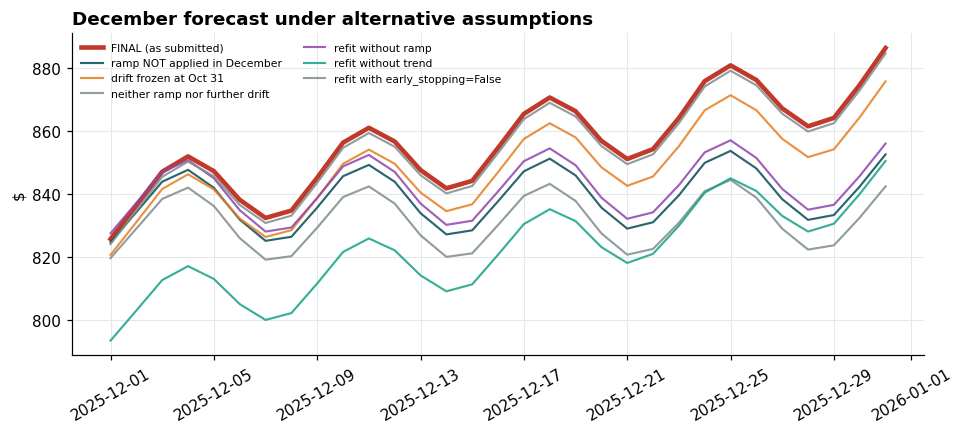

In [7]:
@contextmanager
def patched(**attrs):
    old = {k: getattr(common, k) for k in attrs}
    for k, v in attrs.items(): setattr(common, k, v)
    try: yield
    finally:
        for k, v in old.items(): setattr(common, k, v)

orig_lin = common.linear_features
LAST_TRAIN_DAY = (train.date.max() - common.T0).days / 100
TREND, RAMP = 5, 6                          # column positions in the linear design

def predict_with(modify):
    """Predict December with the ALREADY FITTED model, but alter columns of the linear design at prediction time only."""
    def f(df, dmi_, **kw):
        L = orig_lin(df, dmi_, **kw)
        for col, fn in modify.items(): L[:, col] = fn(L[:, col])
        return L
    with patched(linear_features=f):
        return model.predict(dec_in)

zero = lambda c: np.zeros_like(c)
freeze = lambda c: np.minimum(c, LAST_TRAIN_DAY)
scenarios = {
    "FINAL (as submitted)": dec_pred,
    "ramp NOT applied in December": predict_with({RAMP: zero}),
    "drift frozen at Oct 31": predict_with({TREND: freeze}),
    "neither ramp nor further drift": predict_with({RAMP: zero, TREND: freeze}),
    "refit without ramp": FreightRateModel(dmi, use_ramp=False).fit(train).predict(dec_in),
    "refit without trend": FreightRateModel(dmi, use_trend=False).fit(train).predict(dec_in),
    "refit with early_stopping=False": FreightRateModel(dmi, gbm_params=dict(early_stopping=False)).fit(train).predict(dec_in),
}
assert np.allclose(scenarios["FINAL (as submitted)"], model.predict(dec_in))      # patching is restored

sens = pd.DataFrame({k: {"Dec 1": v[0], "Dec 15": v[14], "Dec 31": v[-1], "Dec mean": v.mean(),
                         "mean vs final %": 100 * (v.mean() / dec_pred.mean() - 1), "Dec 31 vs final %": 100 * (v[-1] / dec_pred[-1] - 1)} for k, v in scenarios.items()}).T
display(sens.round(1))

fig, ax = plt.subplots(figsize=(10, 3.8))
for (k, v), c in zip(scenarios.items(), [RED, TEAL, ORANGE, GREY, "#8E44AD", "#16A085", "#7F8C8D"]):
    ax.plot(dates, v, label=k, lw=3 if k.startswith("FINAL") else 1.4, color=c, alpha=1 if k.startswith("FINAL") else 0.85)
ax.set_title("December forecast under alternative assumptions"); ax.set_ylabel("$"); ax.legend(frameon=False, fontsize=7, ncol=2); ax.tick_params(axis="x", rotation=30)
save_fig(fig, P, "december_sensitivity"); plt.show()

**Interpretation.** If the quarter-end ramp does *not* occur in December, the month's average prediction would fall by roughly 2% and the **last day by about 4%**; if the drift stops, the effect is about 1% by month-end; if both fail, about 3% on average and 5% on the last day. Refitting *without* a term gives a mixed picture (about -1.6% for the ramp, but -4% for the trend, which is larger than not applying it) because removing a term from the fit also shifts the other time coefficients (notebook 3 showed this interaction between trend and ramp). Switching early stopping off changes December by only about 0.2%.

These are **disclosed assumptions, not hedges**: the submitted file uses the final model unchanged. Whether to submit the ramp-free alternative is a judgement call: the ramp is the best-supported explanation of Q1-Q3 (it beat placebos and worked for September out-of-sample) but Q4 has not been observed. The chart should be presented with this caveat.

## 7. Run the unchanged scorer

**Question.** Do both files pass the provided format validation, and does it create the chart?

**Why it matters.** This is the exact check the assessment specifies.

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /home/claude/freight-rate-challenge/outputs/notebooks/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.




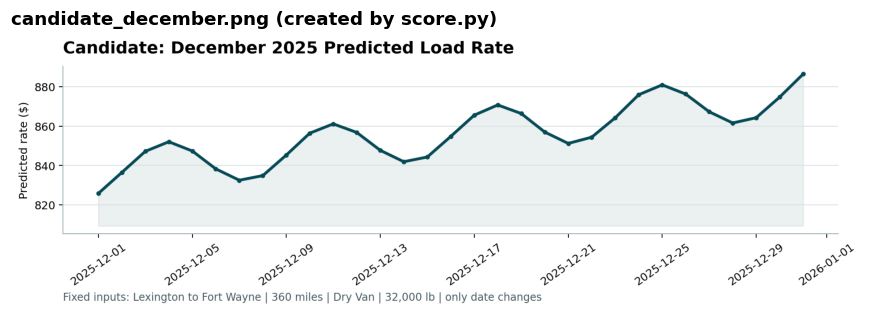

In [8]:
SCORER_DIR = OUT / "scorer_results"
result = subprocess.run([sys.executable, "score.py", "--predictions", str(SUB_PATH), "--december-predictions", str(DEC_PATH), "--output-dir", str(SCORER_DIR)],
                        cwd=P["root"], capture_output=True, text=True)
print(result.stdout); print(result.stderr)
assert result.returncode == 0, "score.py failed"
chart = SCORER_DIR / "candidate_december.png"
fig, ax = plt.subplots(figsize=(10, 4.5)); ax.imshow(plt.imread(chart)); ax.axis("off"); ax.set_title("candidate_december.png (created by score.py)"); plt.show()

## 8. Verify the output files and compare with the script pipeline

**Question.** Are all deliverables present and do the notebook and `train_and_predict.py` agree?

**Why it matters.** Two code paths that should agree are a free consistency test.

In [9]:
def md5(p): return hashlib.md5(Path(p).read_bytes()).hexdigest()
required = {"validation predictions": SUB_PATH, "December chart inputs (filled)": DEC_PATH, "scorer chart": chart}
display(pd.DataFrame({"exists": {k: Path(v).is_file() for k, v in required.items()}, "bytes": {k: Path(v).stat().st_size for k, v in required.items()}}))
assert all(Path(v).is_file() for v in required.values())

script_sub, script_dec = P["root"] / "outputs" / "validation_predictions.csv", P["root"] / "outputs" / "december_chart_inputs.csv"
if script_sub.is_file():
    a, b = pd.read_csv(script_sub), pd.read_csv(SUB_PATH)
    same_ids = (a.load_id == b.load_id).all()
    display(Markdown(f"vs `train_and_predict.py` output: IDs identical **{same_ids}**; byte-identical **{md5(script_sub) == md5(SUB_PATH)}**; "
                     f"max |difference| **${(a.predicted_rate - b.predicted_rate).abs().max():.2f}**"))
    if script_dec.is_file():
        da, db = pd.read_csv(script_dec), pd.read_csv(DEC_PATH)
        display(Markdown(f"December file: byte-identical **{md5(script_dec) == md5(DEC_PATH)}**; max |difference| **${(da.predicted_rate - db.predicted_rate).abs().max():.2f}**"))
else:
    print("script outputs not found (run train_and_predict.py to compare)")

,exists,bytes
validation predictions,True,212995
December chart inputs (filled),True,1827
scorer chart,True,100632


vs `train_and_predict.py` output: IDs identical **True**; byte-identical **True**; max |difference| **$0.00**

December file: byte-identical **True**; max |difference| **$0.00**

**Interpretation.** All deliverables exist and pass the scorer. The notebook and the script pipeline use the same functions, so their outputs should agree; if you run them in a different Python environment than the one that produced `outputs/validation_predictions.csv`, tiny differences are possible and are not errors (the tree model's internal 10% early-stopping split depends on the library version; notebook 3 section 7c; typically well under 1% per row).

## Conclusion

* The submission is reproducible from raw files with one pass through this notebook, or with `python train_and_predict.py`.
* No validation accuracy is claimed: none can be computed. The cross-validated expectation from notebook 3 is about **1.8% MAPE on credible labels** and about **4% MAPE / $94 MAE / ~$620 RMSE if corrupted labels are included**, assuming the daily market index is available and the quarter-end/drift assumptions hold.
* The December chart is an assumption-dependent forecast; its sensitivity is in section 6.